In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [35]:
dataset = pd.read_csv('Position_Salaries.csv')
dataset.head(5)

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [36]:
df = dataset[['Level', 'Salary']]
df.head(5)

,Level,Salary
0,1,45000
1,2,50000
2,3,60000
3,4,80000
4,5,110000


In [37]:
df.corr()  # Correlation matrix to check the relationship between Level and Salary

,Level,Salary
Level,1.000000,0.817949
Salary,0.817949,1.000000


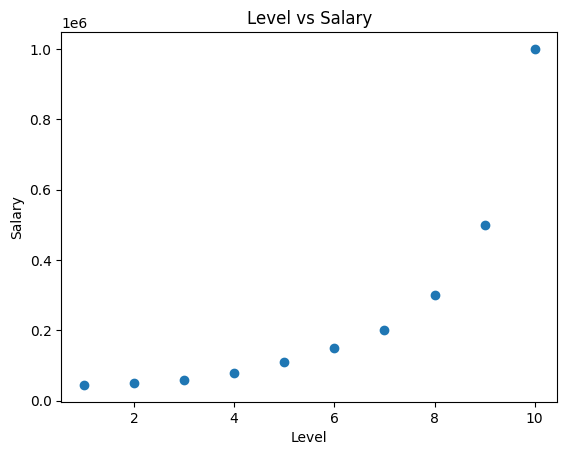

In [38]:
plt.scatter(df['Level'], df['Salary'])
plt.title('Level vs Salary')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.show()

#### Creating Independent and Dependent Variables

In [39]:
# data in the independent variable must be in 2D array format, so we will use double square brackets to select column
x = df[['Level']] # Independent variable
y = df['Salary'] # Dependent variable

#### convert the independent variable to polynomial features

In [40]:

from sklearn.preprocessing import PolynomialFeatures

In [41]:
pf = PolynomialFeatures(degree=2)  # Create polynomial features of degree 2
pf.fit(x) # Fit the polynomial features to the independent variable
x = pf.transform(x)  # Transform the independent variable to polynomial features

#### Split the data into training and testing sets

In [76]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

#### Initialize and Train Polynomial Regression

In [77]:
from sklearn.linear_model import LinearRegression

In [78]:
lr = LinearRegression()  # Initialize the Linear Regression model
lr.fit(x_train, y_train)  # Train the model on the training data

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 0. ,-137634.61, 20502.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.313e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](3,)","[86.95, 1.93, 0. ]"


In [79]:
lr.score(x_test, y_test)  # Evaluate the model on the test data

0.7666492889299912

In [80]:
y_pred = lr.predict(x) 

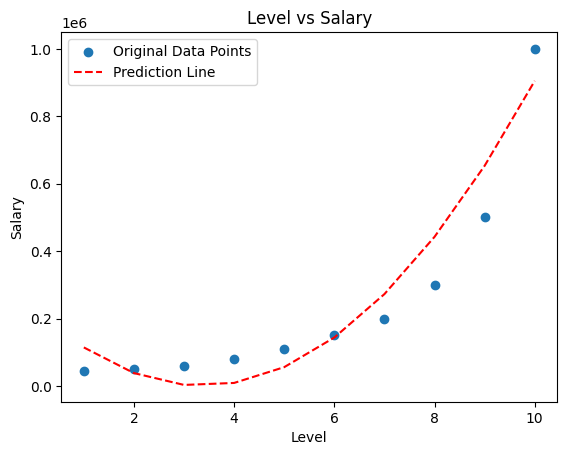

In [82]:
plt.scatter(df['Level'], df['Salary'], label='Original Data Points') # Scatter plot of the original data
plt.plot(df['Level'], y_pred, '--', color='red', label='Prediction Line')  # Plot the regression line
plt.title('Level vs Salary')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.legend()
plt.show()

In [84]:
# Coefficients of the polynomial regression model
lr.coef_

array([      0.        , -137634.60994912,   20502.04918033])

In [85]:
# Intercept of the polynomial regression model
lr.intercept_

np.float64(231288.5104578858)

In [ ]:
# Equation of this polynomial regression model is:
# y = 231288.5104578858 - 137634.60994912 * x + 20502.04918033 * x^2